In [3]:
from sklearn.datasets import load_iris
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data Overview

In [ ]:
# Retrieving the data
shoppersIntentionDF = pd.read_csv('online_shoppers_intention.csv')

In [17]:
shoppersIntentionDF.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

# Data Sctructure

| Feature | Description |
|---|---|
| `Administrative` | Number of administrative pages (Ex. Login, Address) visited by the visitor in that session |
| `Administrative_Duration` | Total time spent on administrative pages (Ex. Login, Address) |
| `Informational` | Number of informational pages (Ex. Contact, Help) visited by the visitor in that session |
| `Informational_Duration` | Total time spent on informational pages (Ex. Contact, Help) |
| `ProductRelated` | Number of product-related pages (Ex. Product Description and price) visited by the visitor in that session |
| `ProductRelated_Duration` | Total time spent on product-related pages (Ex. Product Description and price) |
| `BounceRates` | Percentage of visitors who enter the site and then leave ("bounce") that session (only visits one specific page and then leaves). This is measured by Google Analytics |
| `ExitRates` | Of all pageviews to the page, the percentage that were the last in the session(measured by Google Analytics) |
| `PageValues` | Average value (measured by Google Analytics) of the pages visited in the session, based on how much revenue those pages have historically been associated with before a purchase |
| `SpecialDay` | Closeness of the visit to a specific special day (e.g. Mother's Day, Valentine's Day), when sessions are more likely to end in a transaction |
| `Revenue` | Target variable: whether the session ended in a purchase (`True`) or not (`False`) || `Month` | Month of the year in which the visit took place |
| `OperatingSystems` | Numeric code of the visitor's operating system |
| `Browser` | Numeric code of the visitor's browser |
| `Region` | Numeric code of the visitor's geographic region |
| `TrafficType` | Numeric code of the traffic source |
| `VisitorType` | Type of visitor: `New_Visitor`, `Returning_Visitor` or `Other` |
| `Weekend` | `True` if the visit took place on a weekend |


| Columns | Data type | Variable type |
|---|---|---|
| `Administrative`, `Informational`, `ProductRelated` | int64 | Numerical (discrete) |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` | int64 | Categorical (nominal) |
| `Administrative_Duration`, `Informational_Duration`, `ProductRelated_Duration`, `BounceRates`, `ExitRates`, `PageValues` | float64 | Numerical (continuous) |
| `SpecialDay` | float64 | Numerical (6 discrete values between 0 and 1) |
| `Month` | str | Categorical (ordinal) |
| `VisitorType` | str | Categorical (nominal) |
| `Weekend` | bool | Binary |
| `Revenue` | bool | Binary |

In [22]:
shoppersIntentionDF.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


# Finding Possible Relationships/Trends

In [21]:
shoppersIntentionDF.head(1)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False


**What does a row mean?**

Each row represents one browsing session on an e-commerce website. According to the dataset documentation, the data was built so that each session belongs to a different user within a one-year period, so rows can be treated as independent visits.

For each session, the dataset records the type and number of pages visited and the time spent on them, Google Analytics metrics (bounce rate, exit rate and page value), the closeness of the visit to a special day, the month, whether it was a weekend, technical information (operating system, browser, region and traffic type) and the type of visitor (new or returning).

These are the features used to analyze and predict, among other things, whether a session ends in a purchase, which is reflected in the `Revenue` column.

In [36]:
display(shoppersIntentionDF.describe())
display(shoppersIntentionDF.isna().sum())


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

**Interpretation**

- **Complete data**
  - the `count` row is 12,330 in every column, which equals the total number of rows. If a value were missing, `count` would be lower than 12,330 for that column.
  - The absence of missing values is confirmed with `isna().sum()`.

- **Mean much larger than the median (right-skewed distributions)**

    *Columns:* `Administrative`, `Administrative_Duration`, `Informational`, `Informational_Duration`, `ProductRelated`, `ProductRelated_Duration`, `BounceRates`, `ExitRates`, `PageValues`.

    1. The mean uses every value, so a few very large ones raise it. The median is the middle value and does not depend on how large the extremes are. In a symmetric distribution both are similar.
    2. In these columns the mean is above the median (ex. `ProductRelated_Duration`: mean = 1,195 vs median = 599; `Administrative_Duration`: mean = 81 vs median 7.5).
    3. The maximum is also far from the 75th percentile (ex. `ProductRelated_Duration`: max = 63,974 vs 75th percentile = 1,464), which means the large values are few and extreme.
    4. The standard deviation is larger than the mean in all of these columns (ex. `ProductRelated_Duration`: = 1,914 vs = 1,195), which also indicates high dispersion.

   *Conclusion*: a few very long or very active sessions pull the mean up, so the median describes a typical session better. The histograms are needed to confirm the exact shape.

- **Sparse columns (mostly zeros)**

   *Columns:* `Informational`, `Informational_Duration`, `PageValues` and `SpecialDay`. `Administrative`, `Administrative_Duration` and `BounceRates` are partially sparse (their 25th percentile is 0).

    1. In the first four columns the 25th, 50th and 75th percentiles are all 0, and the minimum is 0. These variables cannot be negative, so at least 75% of the rows are exactly 0.
    2. These zeros are valid values, not missing data, because `count` is complete (12,330 in every column).
    3. The mean is not representative. For example, `Informational` has a mean of 0.50 but a median of 0: at most 25% of the sessions have values above 0 (up to a maximum of 24), and those few sessions raise the overall average.

   *Conclusion*: the information in these columns is concentrated in a minority of sessions, so the mean should not be used to describe a typical session.

### Shopping Sessions Relative to Total Sessions per Month

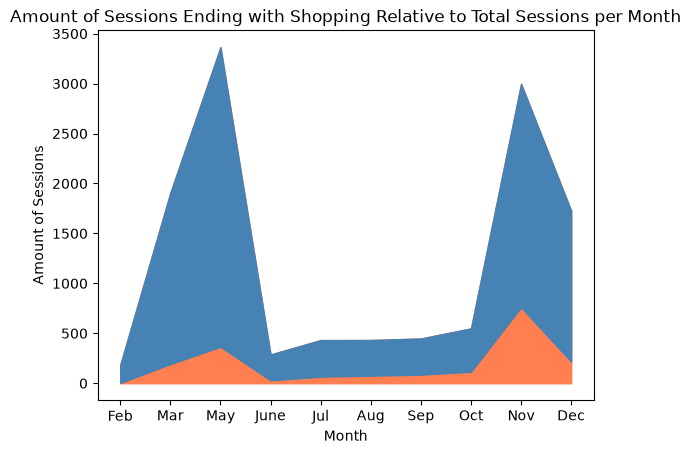

In [8]:
x = shopping_months_order["Month"]
total_sessions = shopping_months_order["total_revenue"]
purchases = shopping_months_order["observations"]

plt.fill_between(
    x, 
    0, 
    purchases, 
    color = "coral"
)
plt.fill_between(
    x, 
    purchases, 
    total_sessions, 
    color = "steelblue"
)
plt.title("Amount of Sessions Ending with Shopping Relative to Total Sessions per Month")
plt.xlabel("Month")
plt.ylabel("Amount of Sessions")
plt.show()

### Distance to 'Special Day'

In [ ]:
Special_day = (
    shoppersIntentionDF.groupby("Month")["SpecialDay"]
    .mean()
    .rename("Closeness to Special Day")
    .reset_index()
)

Special_day_shopping = counts.merge(
    Special_day, 
    on = "Month", 
    how = "inner", 
    validate = "one_to_one"
)

Special_day_shopping_order = Special_day_shopping.reindex(order)
Special_day_shopping_order


,Month,observations,Closeness to Special Day
2,Feb,184,0.233696
5,Mar,1907,0.000000
6,May,3364,0.212366
4,June,288,0.000000
3,Jul,432,0.000000
0,Aug,433,0.000000
9,Sep,448,0.000000
8,Oct,549,0.000000
7,Nov,2998,0.000000
1,Dec,1727,0.000000


In [ ]:
shoppersIntentionDF[shoppersIntentionDF['SpecialDay'] > 0].groupby('Month').count()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
Month,,,,,,,,,,,,,,,,,
Feb,79,79,79,79,79,79,79,79,79,79,79,79,79,79,79,79,79
May,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172


## Classification

In [ ]:
missing_values = shoppersIntentionDF.isna().sum()
print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


Class distribution:
Revenue
False    10422
True      1908
Name: count, dtype: int64


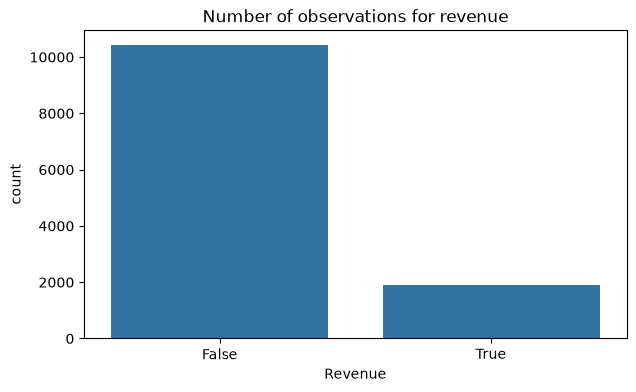

Potential 


In [ ]:
print("Class distribution:")
print(shoppersIntentionDF["Revenue"].value_counts().sort_index())

plt.figure(figsize=(7, 4))
sns.countplot(data=shoppersIntentionDF, x="Revenue")
plt.title("Number of observations for revenue")
plt.show()

print("Potential ")

In [ ]:
numeric_features = []
for column in shoppersIntentionDF.columns:
    if column != "Revenue":
        numeric_features.append(column)
